In [9]:
import pandas as pd

# 1. Load all three raw datasets using the correct root path (no '../')
cbk_df = pd.read_csv("data/raw/cbk_macro_indicators.csv")
cpi_df = pd.read_csv("data/raw/knbs_cpi_monthly.csv")
maize_df = pd.read_csv("data/raw/maize_market_prices_raw.csv")

# 2. Verify CBK Macroeconomic Indicators
print("=" * 60)
print("1. CBK MACROECONOMIC INDICATORS VERIFICATION")
print("=" * 60)
print(cbk_df.info())
print("\nMissing Values:")
print(cbk_df.isnull().sum())
print("\nSummary Statistics:")
display(cbk_df.describe())

# 3. Verify KNBS CPI Monthly Data
print("\n" + "=" * 60)
print("2. KNBS CPI MONTHLY VERIFICATION")
print("=" * 60)
print(cpi_df.info())
print("\nMissing Values:")
print(cpi_df.isnull().sum())
print("\nSummary Statistics:")
display(cpi_df.describe())

# 4. Verify Maize Market Prices Raw Data
print("\n" + "=" * 60)
print("3. MAIZE MARKET PRICES RAW VERIFICATION")
print("=" * 60)
print(maize_df.info())
print("\nMissing Values:")
print(maize_df.isnull().sum())
print("\nUnique Counties Found:")
print(maize_df["county"].unique() if "county" in maize_df.columns else "No county column found")
print("\nSummary Statistics:")
display(maize_df.describe())

1. CBK MACROECONOMIC INDICATORS VERIFICATION
<class 'pandas.DataFrame'>
RangeIndex: 132 entries, 0 to 131
Data columns (total 3 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   date                   132 non-null    str    
 1   exchange_rate_usd_kes  127 non-null    float64
 2   central_bank_rate      132 non-null    float64
dtypes: float64(2), str(1)
memory usage: 4.5 KB
None

Missing Values:
date                     0
exchange_rate_usd_kes    5
central_bank_rate        0
dtype: int64

Summary Statistics:


,exchange_rate_usd_kes,central_bank_rate
count,127.000000,132.000000
mean,114.311496,10.988636
std,14.807230,1.302473
min,-15.200000,9.500000
25%,107.205000,10.000000
50%,114.340000,10.500000
75%,123.160000,12.500000
max,131.920000,13.000000



2. KNBS CPI MONTHLY VERIFICATION
<class 'pandas.DataFrame'>
RangeIndex: 132 entries, 0 to 131
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   date       132 non-null    str    
 1   cpi_index  128 non-null    float64
dtypes: float64(1), str(1)
memory usage: 3.5 KB
None

Missing Values:
date         0
cpi_index    4
dtype: int64

Summary Statistics:


,cpi_index
count,128.000000
mean,208.076094
std,34.398188
min,150.000000
25%,176.965000
50%,208.810000
75%,239.277500
max,268.000000



3. MAIZE MARKET PRICES RAW VERIFICATION
<class 'pandas.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 3 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   date                   660 non-null    str    
 1   county                 660 non-null    str    
 2   maize_retail_price_kg  645 non-null    float64
dtypes: float64(1), str(2)
memory usage: 28.1 KB
None

Missing Values:
date                      0
county                    0
maize_retail_price_kg    15
dtype: int64

Unique Counties Found:
<ArrowStringArray>
['Nairobi', 'Nakuru', 'Uasin Gishu (Eldoret)', 'Kisumu', 'Mombasa']
Length: 5, dtype: str

Summary Statistics:


,maize_retail_price_kg
count,645.000000
mean,165.610109
std,3060.704289
min,23.310000
25%,38.850000
50%,45.060000
75%,51.830000
max,77777.000000


In [3]:
import pandas as pd
import numpy as np
import os

os.makedirs("data/processed", exist_ok=True)
print("=" * 60)
print("COMPREHENSIVE DATA CLEANING PIPELINE")
print("=" * 60)

# Cleaning the Central Bank of Kenya (CBK) Dataset
print("\n[1/3] Processing CBK Macroeconomic Indicators...")
cbk_df = pd.read_csv("data/raw/cbk_macro_indicators.csv")
cbk_df = cbk_df.drop_duplicates().copy()
cbk_df = cbk_df.dropna(subset=["date"]).copy()
cbk_df["date"] = pd.to_datetime(cbk_df["date"], errors="coerce")
cbk_df = cbk_df.dropna(subset=["date"]).sort_values("date").reset_index(drop=True)
cbk_df["exchange_rate_usd_kes"] = cbk_df["exchange_rate_usd_kes"].apply(lambda x: np.nan if x < 0 else x)
cbk_df["exchange_rate_usd_kes"] = (
    cbk_df["exchange_rate_usd_kes"]
    .interpolate(method="linear")
    .ffill()
    .bfill()
)
cbk_df["central_bank_rate"] = (
    cbk_df["central_bank_rate"]
    .interpolate(method="linear")
    .ffill()
    .bfill()
)
cbk_path = "data/processed/cbk_macro_indicators_clean.csv"
cbk_df.to_csv(cbk_path, index=False)
print(f" -> Saved to {cbk_path}")
print(f" -> Final Null Count: {cbk_df.isnull().sum().sum()} (Target: 0)")

# Cleaning the KNBS Consumer Price Index (CPI) Dataset
print("\n[2/3] Processing KNBS CPI Monthly Data...")
cpi_df = pd.read_csv("data/raw/knbs_cpi_monthly.csv")
cpi_df = cpi_df.drop_duplicates().copy()
cpi_df = cpi_df.dropna(subset=["date"]).copy()
cpi_df["date"] = pd.to_datetime(cpi_df["date"], errors="coerce")
cpi_df = cpi_df.dropna(subset=["date"]).sort_values("date").reset_index(drop=True)
cpi_df["cpi_index"] = (
    cpi_df["cpi_index"]
    .interpolate(method="linear")
    .ffill()
    .bfill()
)
cpi_path = "data/processed/knbs_cpi_monthly_clean.csv"
cpi_df.to_csv(cpi_path, index=False)
print(f" -> Saved to {cpi_path}")
print(f" -> Final Null Count: {cpi_df.isnull().sum().sum()} (Target: 0)")

# Cleaning the Maize Market Prices Dataset
print("\n[3/3] Processing Maize Market Prices Data...")
maize_df = pd.read_csv("data/raw/maize_market_prices_raw.csv")
maize_df = maize_df.drop_duplicates().copy()
maize_df["date"] = pd.to_datetime(maize_df["date"], errors="coerce")
maize_df["county"] = maize_df["county"].str.strip().str.title()
maize_df["maize_retail_price_kg"] = maize_df["maize_retail_price_kg"].apply(
    lambda x: np.nan if x > 500 or x < 0 else x
)
maize_df["maize_retail_price_kg"] = maize_df.groupby("county")["maize_retail_price_kg"].transform(
    lambda x: x.fillna(x.median())
)
global_median_price = maize_df["maize_retail_price_kg"].median()
maize_df["maize_retail_price_kg"] = maize_df["maize_retail_price_kg"].fillna(global_median_price)
maize_df = maize_df.sort_values(["date", "county"]).reset_index(drop=True)
maize_path = "data/processed/maize_market_prices_clean.csv"
maize_df.to_csv(maize_path, index=False)
print(f" -> Saved to {maize_path}")
print(f" -> Final Null Count: {maize_df.isnull().sum().sum()} (Target: 0)")

print("\n" + "=" * 60)
print("SUCCESS: 100% DATA CLEANING PIPELINE COMPLETED WITH ZERO NULLS")
print("=" * 60)

COMPREHENSIVE DATA CLEANING PIPELINE

[1/3] Processing CBK Macroeconomic Indicators...
 -> Saved to data/processed/cbk_macro_indicators_clean.csv
 -> Final Null Count: 0 (Target: 0)

[2/3] Processing KNBS CPI Monthly Data...
 -> Saved to data/processed/knbs_cpi_monthly_clean.csv
 -> Final Null Count: 0 (Target: 0)

[3/3] Processing Maize Market Prices Data...
 -> Saved to data/processed/maize_market_prices_clean.csv
 -> Final Null Count: 0 (Target: 0)

SUCCESS: 100% DATA CLEANING PIPELINE COMPLETED WITH ZERO NULLS


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load individual cleaned files from the correct local path
cbk = pd.read_csv("data/processed/cbk_macro_indicators_clean.csv")
cpi = pd.read_csv("data/processed/knbs_cpi_monthly_clean.csv")
maize = pd.read_csv("data/processed/maize_market_prices_clean.csv")

# Ensure date columns are formatted for merging
cbk["date"] = pd.to_datetime(cbk["date"])
cpi["date"] = pd.to_datetime(cpi["date"])
maize["date"] = pd.to_datetime(maize["date"])

# Merge datasets together on date to create the master panel
df = pd.merge(maize, cpi, on="date", how="inner")
df = pd.merge(df, cbk, on="date", how="inner")

# Save the master panel
df.to_csv("data/processed/kenya_macro_maize_master_cleaned.csv", index=False)
print("-> Master panel successfully created and saved!")

-> Master panel successfully created and saved!


-> All data integrity assertions passed successfully!

=== PHASE 2: CLEANED MASTER PANEL SUMMARY ===


,date,maize_retail_price_kg,cpi_index,exchange_rate_usd_kes,central_bank_rate
count,660,660.000000,660.000000,660.000000,660.000000
mean,2020-06-16 02:10:54.545454,45.096500,209.000606,115.276439,10.988636
min,2015-01-01 00:00:00,23.310000,150.000000,100.150000,9.500000
25%,2017-09-23 12:00:00,39.080000,177.550000,107.217500,10.000000
50%,2020-06-16 00:00:00,45.060000,209.000000,114.465000,10.500000
75%,2023-03-08 18:00:00,51.420000,240.450000,123.150000,12.500000
max,2025-12-01 00:00:00,69.070000,268.000000,131.920000,13.000000
std,NaN,9.000138,34.282325,9.224531,1.298514


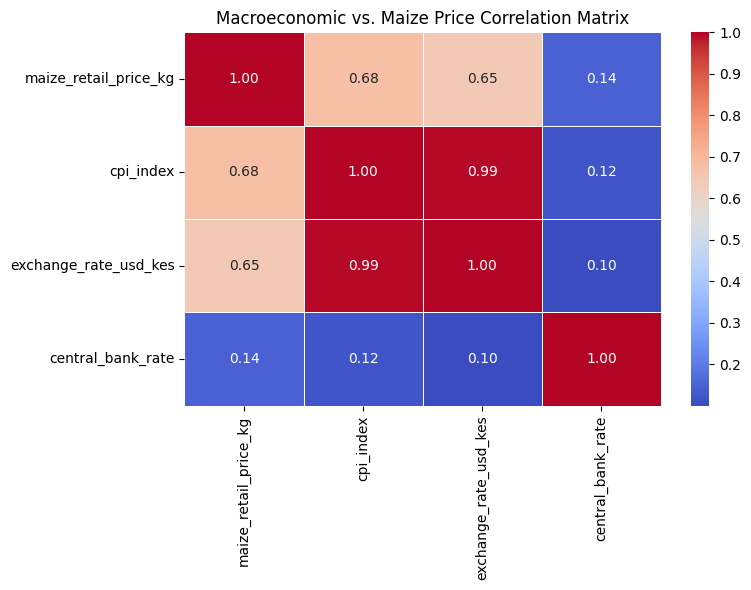

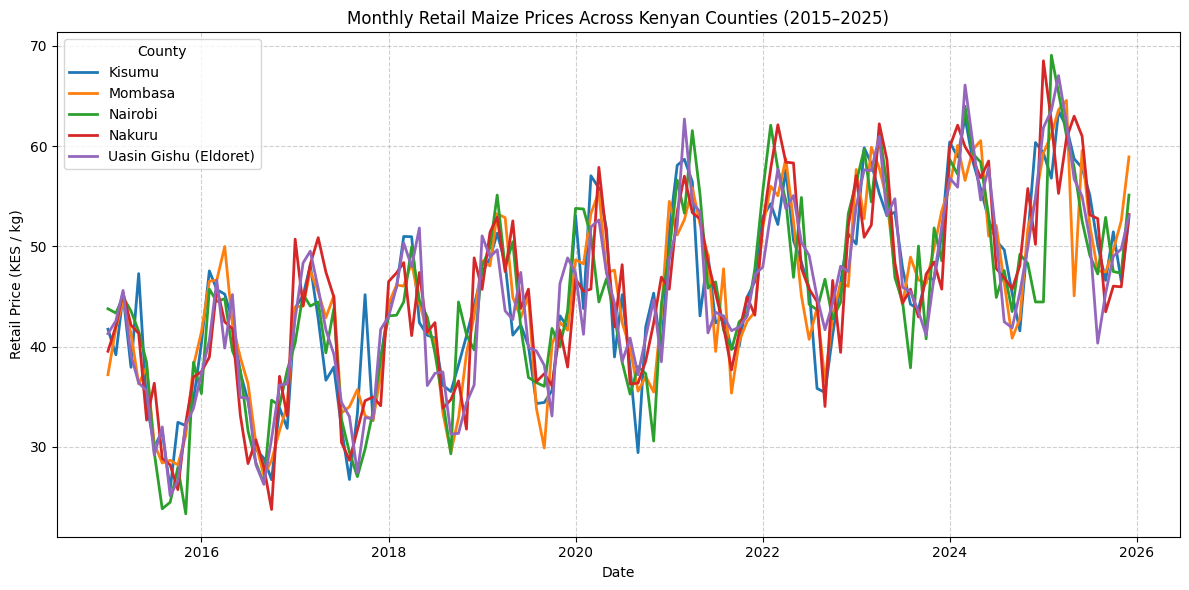

C:\Users\USER\AppData\Local\Temp\ipykernel_17576\2871758603.py:45: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="county", y="maize_retail_price_kg", palette="Set2")


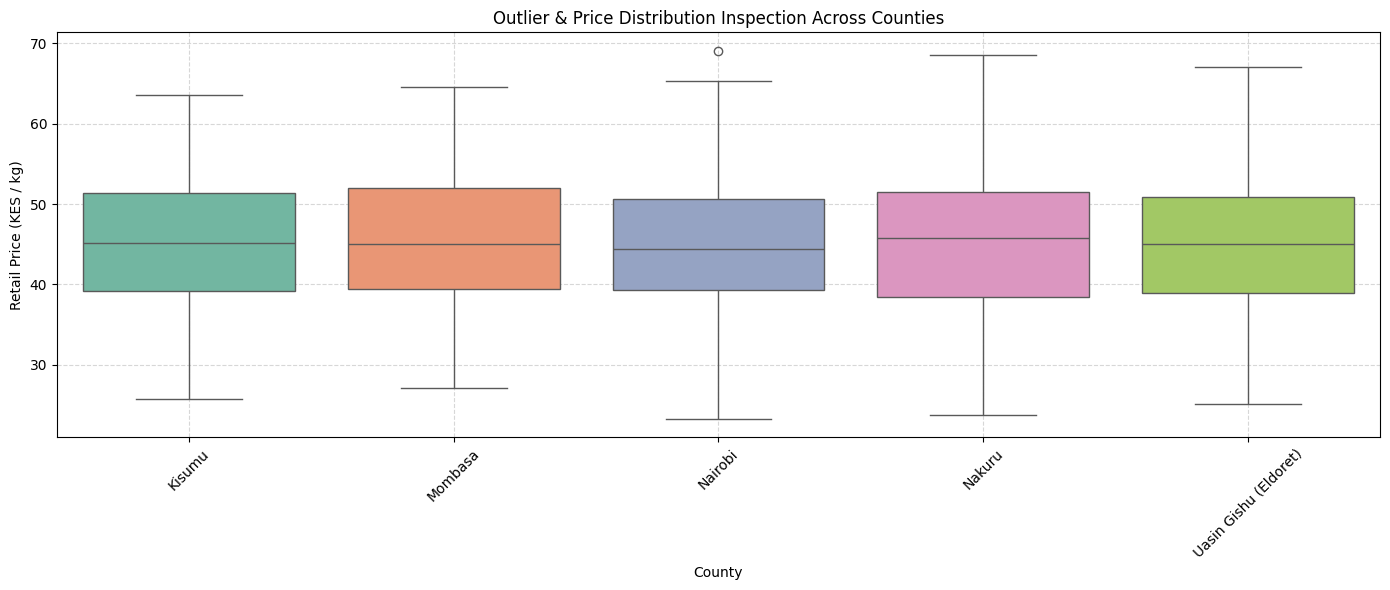

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load cleaned master dataset
df = pd.read_csv("data/processed/kenya_macro_maize_master_cleaned.csv")
df["date"] = pd.to_datetime(df["date"])

# 0. Pipeline Data Integrity Assertions (Validating before visualization)
def validate_master_dataset(data):
    assert not data.empty, "Pipeline error: The dataset is empty!"
    assert data["date"].notnull().all(), "Validation failed: Null values found in 'date' column."
    assert data["cpi_index"].dtype in ['float64', 'int64'], "Validation failed: 'cpi_index' must be numeric."
    assert (data["maize_retail_price_kg"] >= 0).all(), "Validation failed: Negative maize prices detected!"
    print("-> All data integrity assertions passed successfully!")

validate_master_dataset(df)

# 1. Summary statistics of our cleaned panel data
print("\n=== PHASE 2: CLEANED MASTER PANEL SUMMARY ===")
display(df.describe())

# 2. Correlation Matrix to check macroeconomic drivers
plt.figure(figsize=(8, 6))
numeric_cols = ["maize_retail_price_kg", "cpi_index", "exchange_rate_usd_kes", "central_bank_rate"]
corr = df[numeric_cols].corr()
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Macroeconomic vs. Maize Price Correlation Matrix")
plt.tight_layout()
plt.show()

# 3. Regional Price Trend Check (Mean maize price over time by county)
plt.figure(figsize=(12, 6))
sns.lineplot(data=df, x="date", y="maize_retail_price_kg", hue="county", linewidth=2)
plt.title("Monthly Retail Maize Prices Across Kenyan Counties (2015–2025)")
plt.xlabel("Date")
plt.ylabel("Retail Price (KES / kg)")
plt.legend(title="County")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

# 4. Outlier Inspection (Boxplots by County to check spread and extreme values)
plt.figure(figsize=(14, 6))
sns.boxplot(data=df, x="county", y="maize_retail_price_kg", palette="Set2")
plt.title("Outlier & Price Distribution Inspection Across Counties")
plt.xlabel("County")
plt.ylabel("Retail Price (KES / kg)")
plt.xticks(rotation=45)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()